In [22]:
# Loading and Preprocessing
import pandas as pd
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

ds = pd.read_csv("./datasets/adult_income.csv")

le = LabelEncoder()

for col in ds.columns:
    ds[col] = le.fit_transform(ds[col])

X = ds[["age", "workclass", "sex"]]
Y = ds.iloc[:, -1]

xtr, xte, ytr, yte = train_test_split(X, Y, random_state = 42, test_size = 0.2)


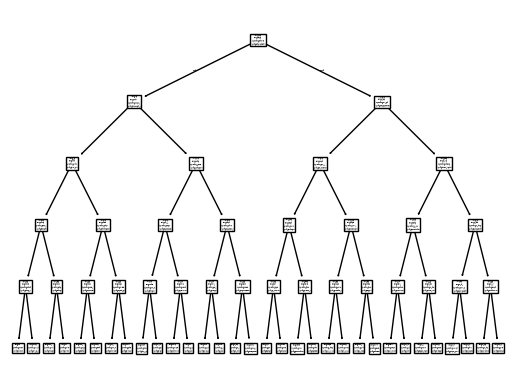

In [24]:
# Decision Tree Classifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

dtc = DecisionTreeClassifier(max_depth=5)
dtc.fit(xtr, ytr)
dtc_predict = dtc.predict(xte)

plot_tree(dtc)
plt.show()


In [27]:
# Logistic Regression
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression()
lr.fit(xtr, ytr)
lr_predict = lr.predict(xte)

In [30]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score

def findMetrics(ytrue, ypredict, name):
    print(f"--- {name} ---")
    print(f"F1 => {f1_score(ytrue, ypredict)}")
    print(f"Precision => {precision_score(ytrue, ypredict)}")
    print(f"Recall => {recall_score(ytrue, ypredict)}")
    print(f"Accuracy => {accuracy_score(ytrue, ypredict)}")


findMetrics(yte, dtc_predict, "DecisionTreeClassifier")
findMetrics(yte, lr_predict, "LogisticRegression")

--- DecisionTreeClassifier ---
F1 => 0.11403508771929824
Precision => 0.6559633027522935
Recall => 0.062445414847161575
Accuracy => 0.7725458081686969
--- LogisticRegression ---
F1 => 0.116751269035533
Precision => 0.344017094017094
Recall => 0.0703056768558952
Accuracy => 0.7506397788924147
